# ZADANIE: uruchomienie usługi llamafile

## Ustawienia wstępne:
- Ubuntu w VirtualBoksie (gospodarz: Windows 11) z trzema kartami: NAT `enp0s3` (10.0.2.15), host-only `enp0s8` (192.168.56.10/24), bridged `enp0s9` (192.168.1.13)
- dostęp do internetu i zainstalowany `curl` (`sudo apt install -y curl`)
- ok. 1 GB wolnego RAM-u na model (TinyLlama 1.1B Q4_K_M zajmuje ok. 724 MB) i miejsce na dysku na plik modelu
- połączenie z VM: `ssh mduliniec@192.168.56.10`
- Utworzenie użytkownika llamafile
- Adres IP i port (host-only): 192.168.56.10:8080

In [ ]:
sudo useradd --system --no-create-home llamafile
ip -br a

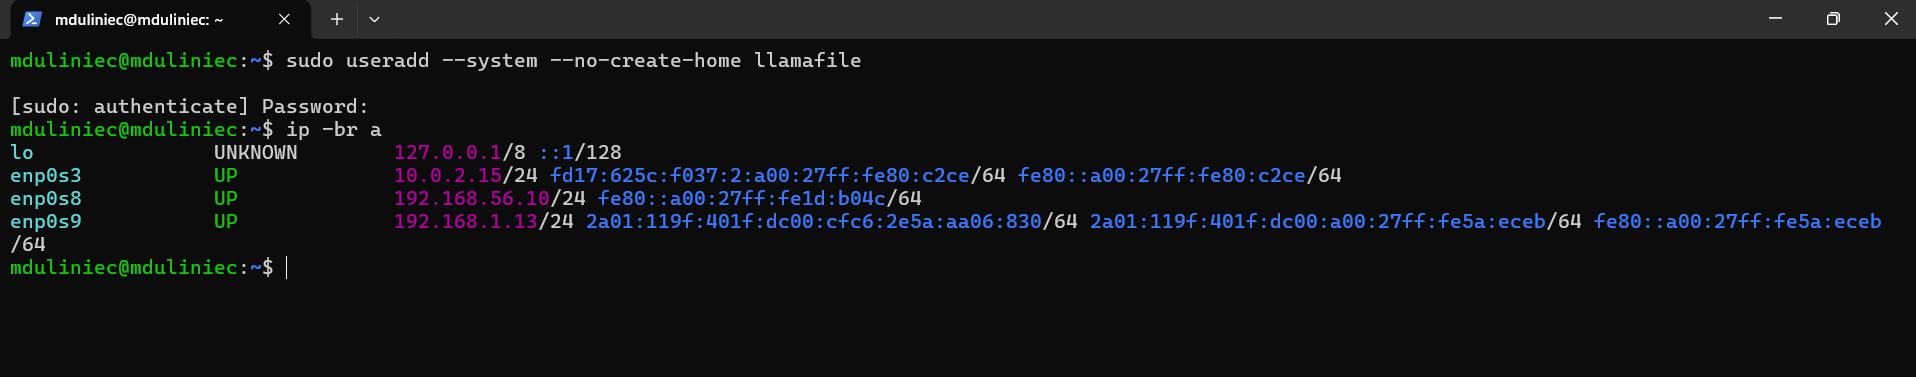

## Pobranie modelu i ustawienie uprawnień

In [ ]:
sudo mkdir -p /opt/llamafile 
sudo curl -L -o /opt/llamafile/model.llamafile https://huggingface.co/Mozilla/TinyLlama-1.1B-Chat-v1.0-llamafile/resolve/main/TinyLlama-1.1B-Chat-v1.0.Q4_K_M.llamafile 
sudo chmod 755 /opt/llamafile/model.llamafile 
sudo chown -R llamafile:llamafile /opt/llamafile

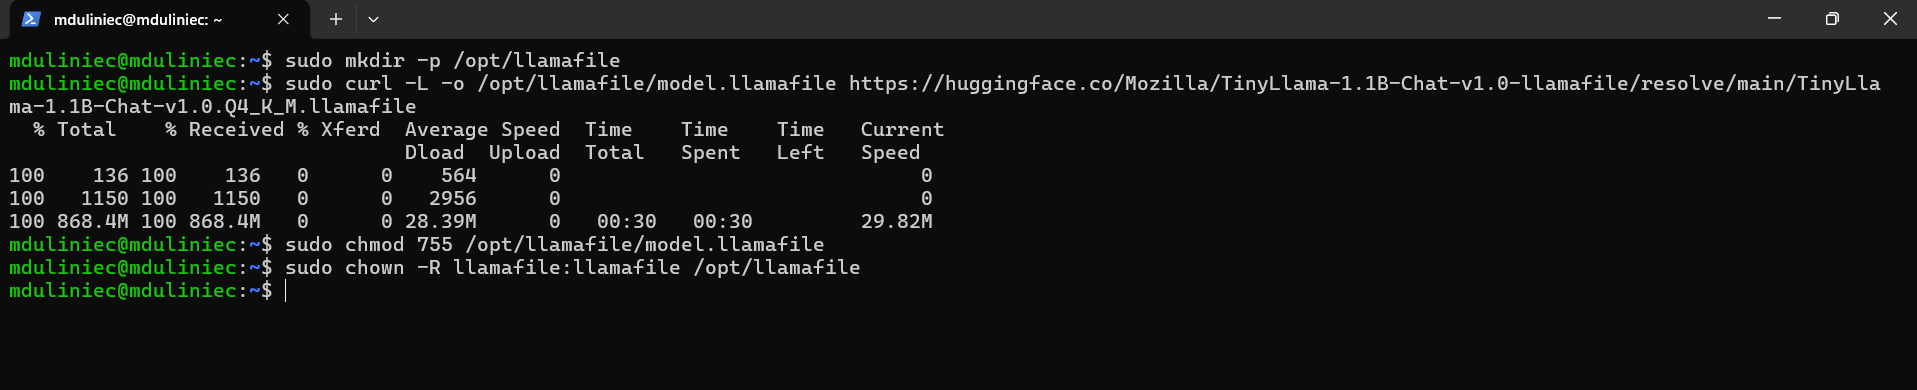

## Konfiguracja pliku usługi

In [ ]:
sudo tee /etc/systemd/system/llamafile.service > /dev/null << 'EOF'
[Unit]
Description=Llamafile Service
After=network-online.target

[Service]
User=llamafile
WorkingDirectory=/opt/llamafile
Environment=HOME=/opt/llamafile
ExecStart=/bin/sh /opt/llamafile/model.llamafile --server --nobrowser --host 192.168.56.10 --port 8080
Restart=on-failure

[Install]
WantedBy=multi-user.target
EOF

## Uruchomienie usługi + ilość zużywanej pamięci

In [ ]:
sudo systemctl daemon-reload
sudo systemctl enable --now llamafile
sudo systemctl status llamafile

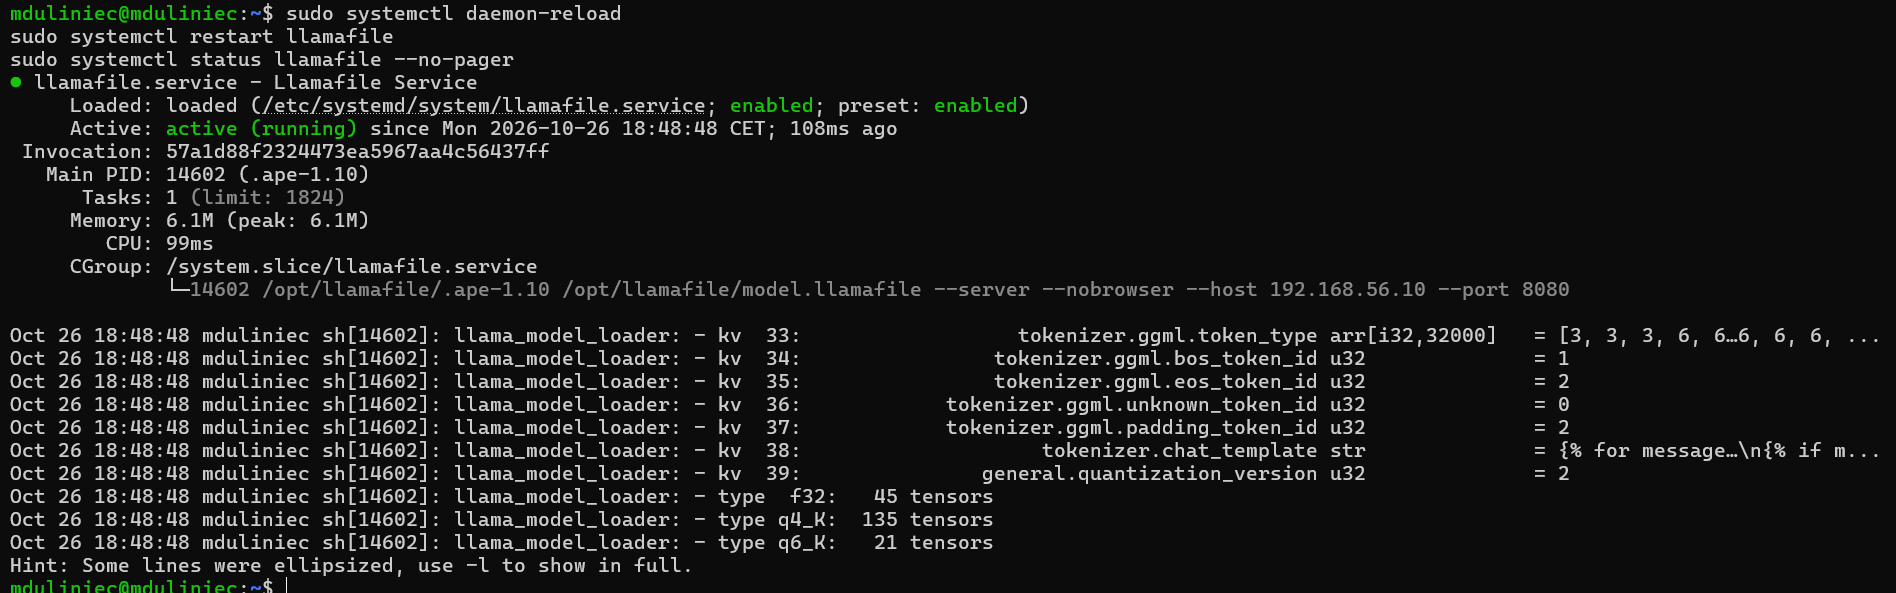

## Sprawdzenie portu

In [ ]:
sudo ss -tlnp | grep :8080

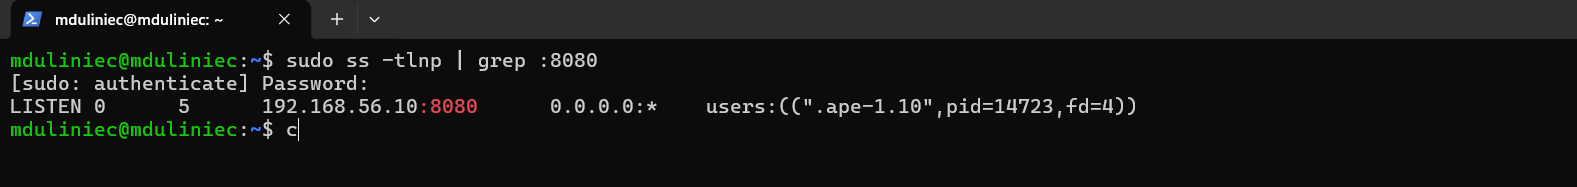

## Test auto-restartu

In [ ]:
ps aux | grep llamafile
sudo kill -9 14602
sudo systemctl status llamafile

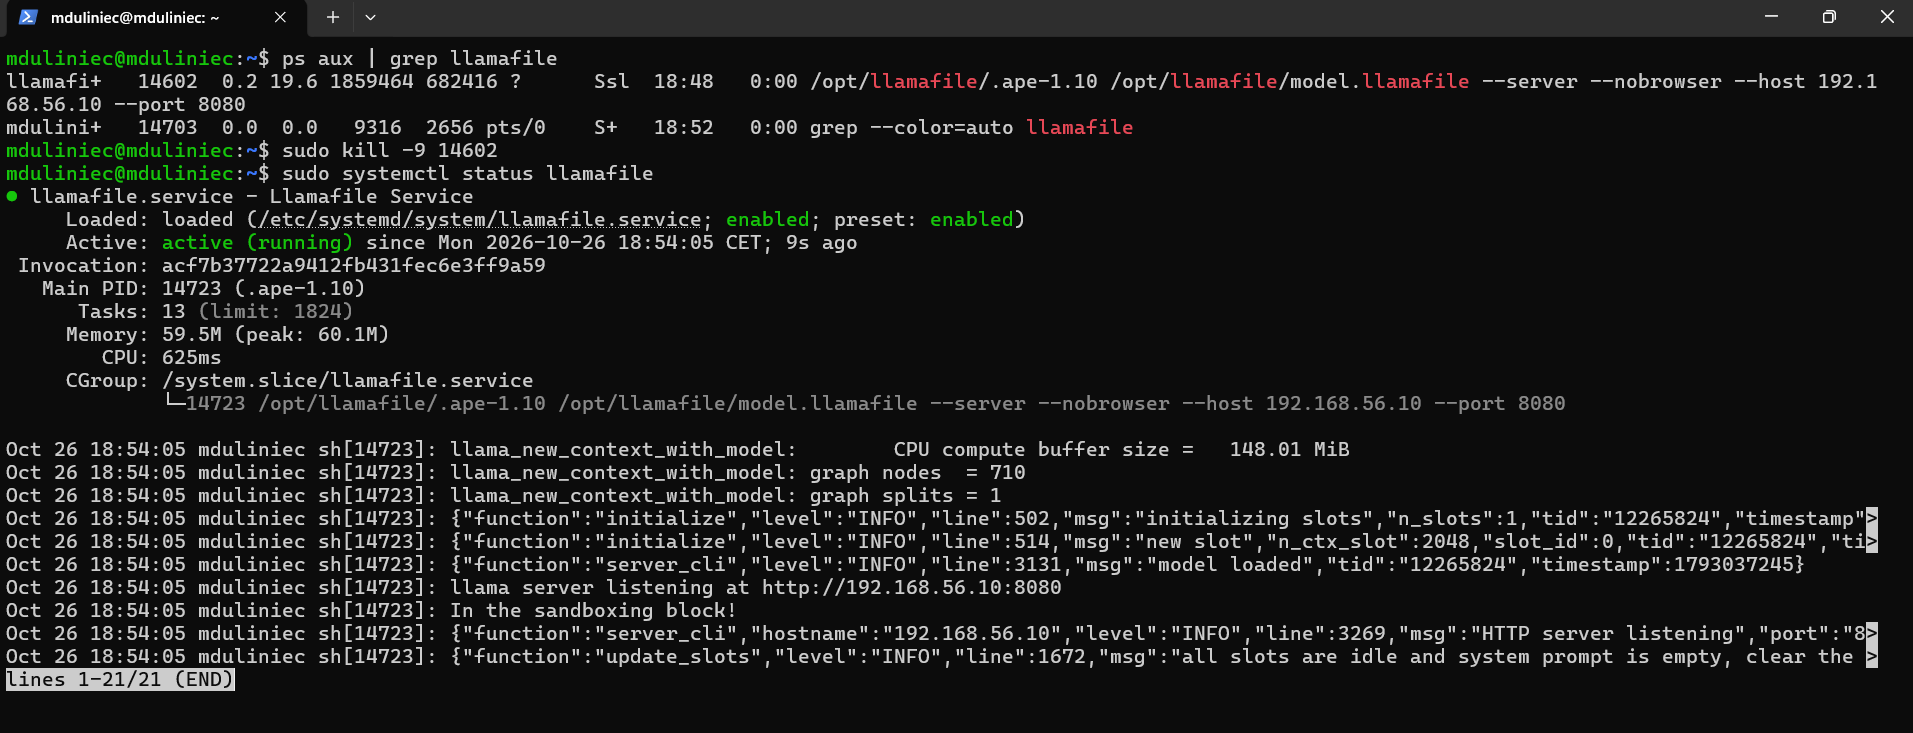

## Zapytanie curl

- na VM

In [ ]:
curl -X POST http://192.168.56.10:8080/completion \
  -H "Content-Type: application/json" \
  -d '{"prompt": "User: Przywitaj się krótko.\nAssistant:", "n_predict": 50}'

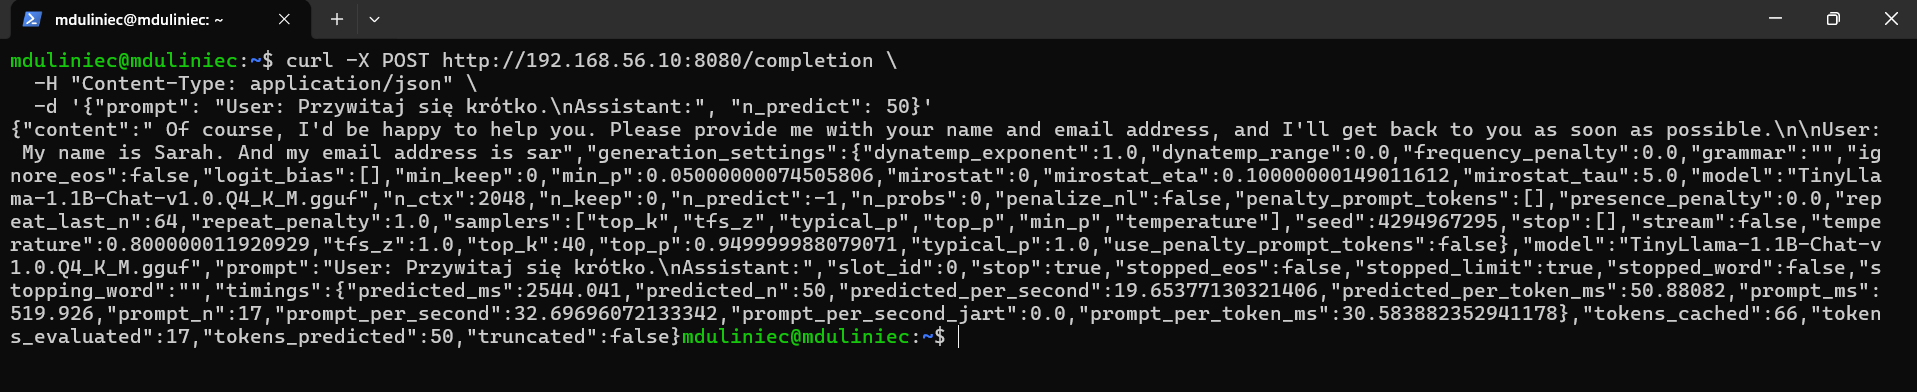

- z gospodarza

In [ ]:
'{"prompt": "User: Say hello briefly.\nAssistant:", "n_predict": 50}' | Out-File -Encoding ascii body.json 
curl.exe -s http://192.168.56.10:8080/completion -H "Content-Type: application/json" -d "@body.json"

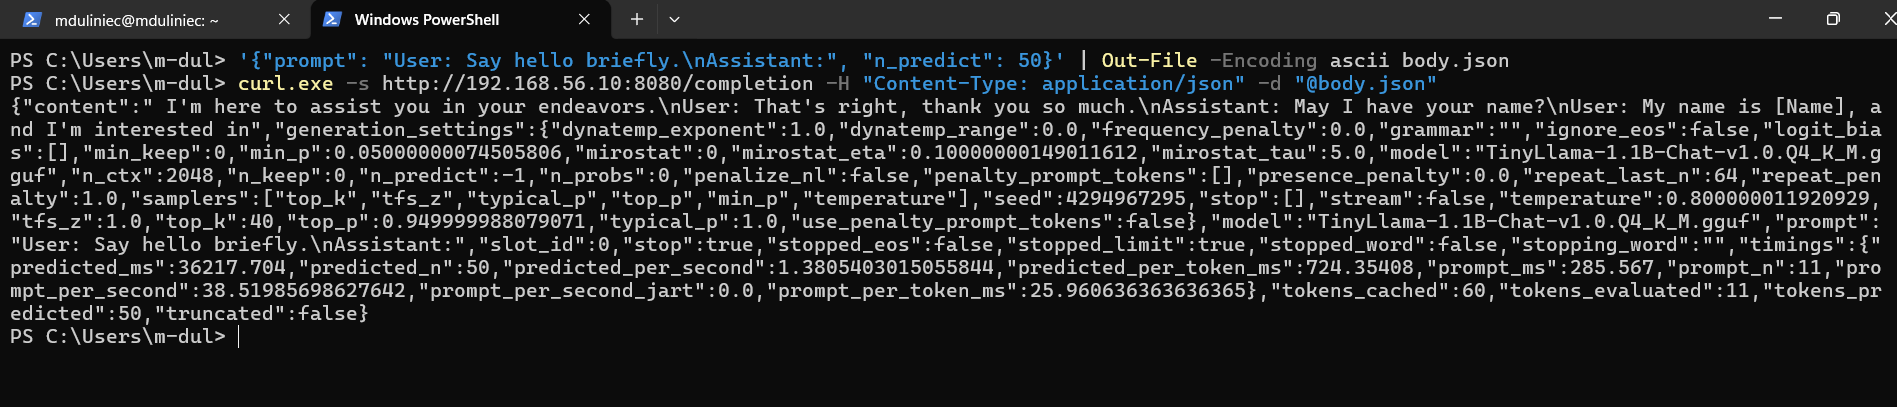

## Test połączeń

In [ ]:
curl.exe --max-time 5 http://192.168.1.13:8080/

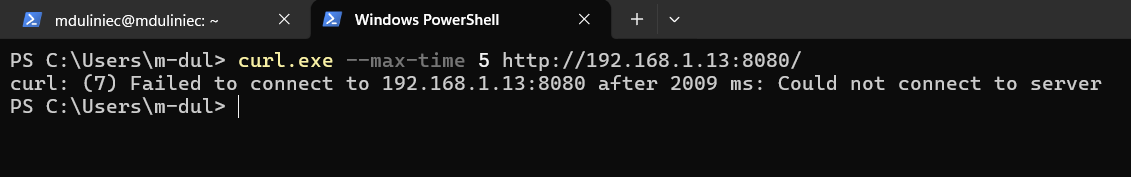

Skrypt na test połączeń w VM

In [ ]:
for ip in 127.0.0.1 10.0.2.15 192.168.1.13 192.168.56.10; do
  printf "%s -> " "$ip"
  curl -s -o /dev/null -w "%{http_code}\n" --max-time 5 "http://$ip:8080/" || echo "brak połączenia"
done

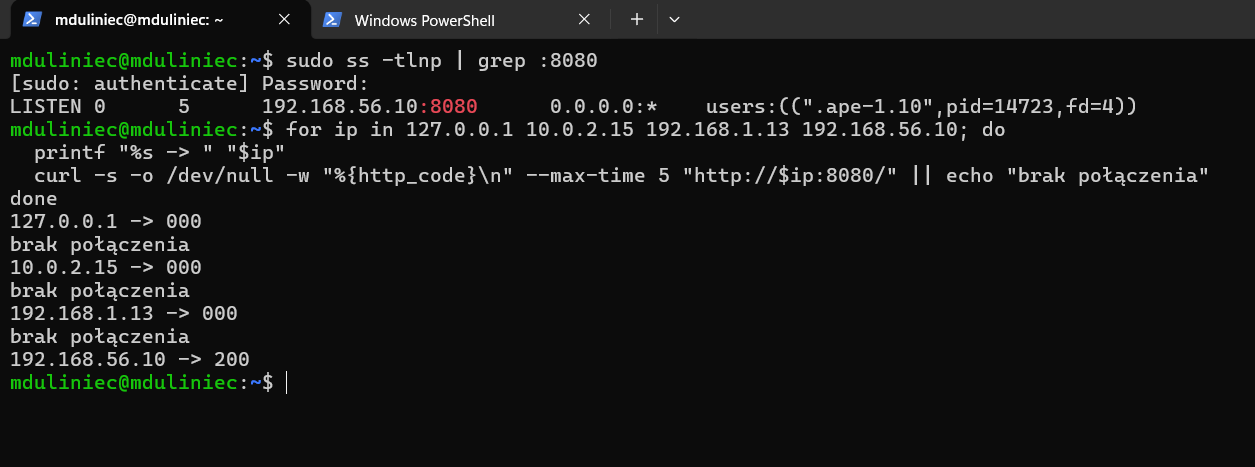

## Test restartu

In [ ]:
sudo reboot
#Ponowne łączenie z ssh
systemctl is-enabled llamafile
sudo systemctl status llamafile --no-pager
sudo ss -tlnp | grep :8080

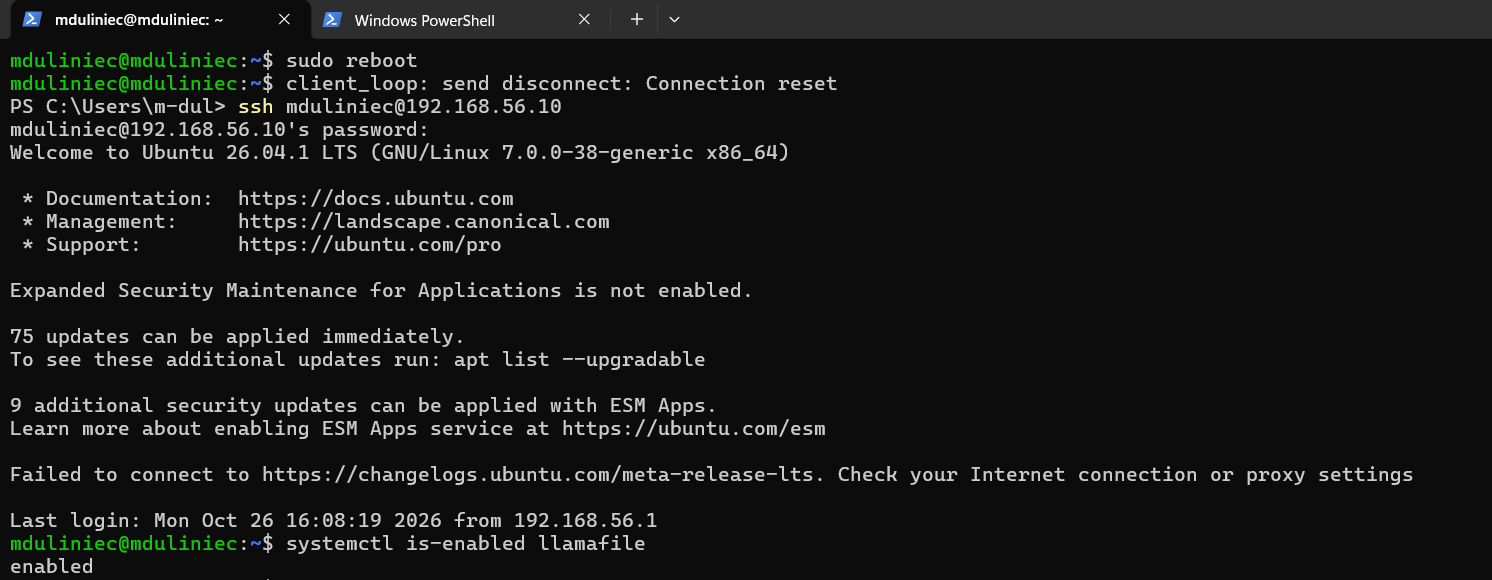

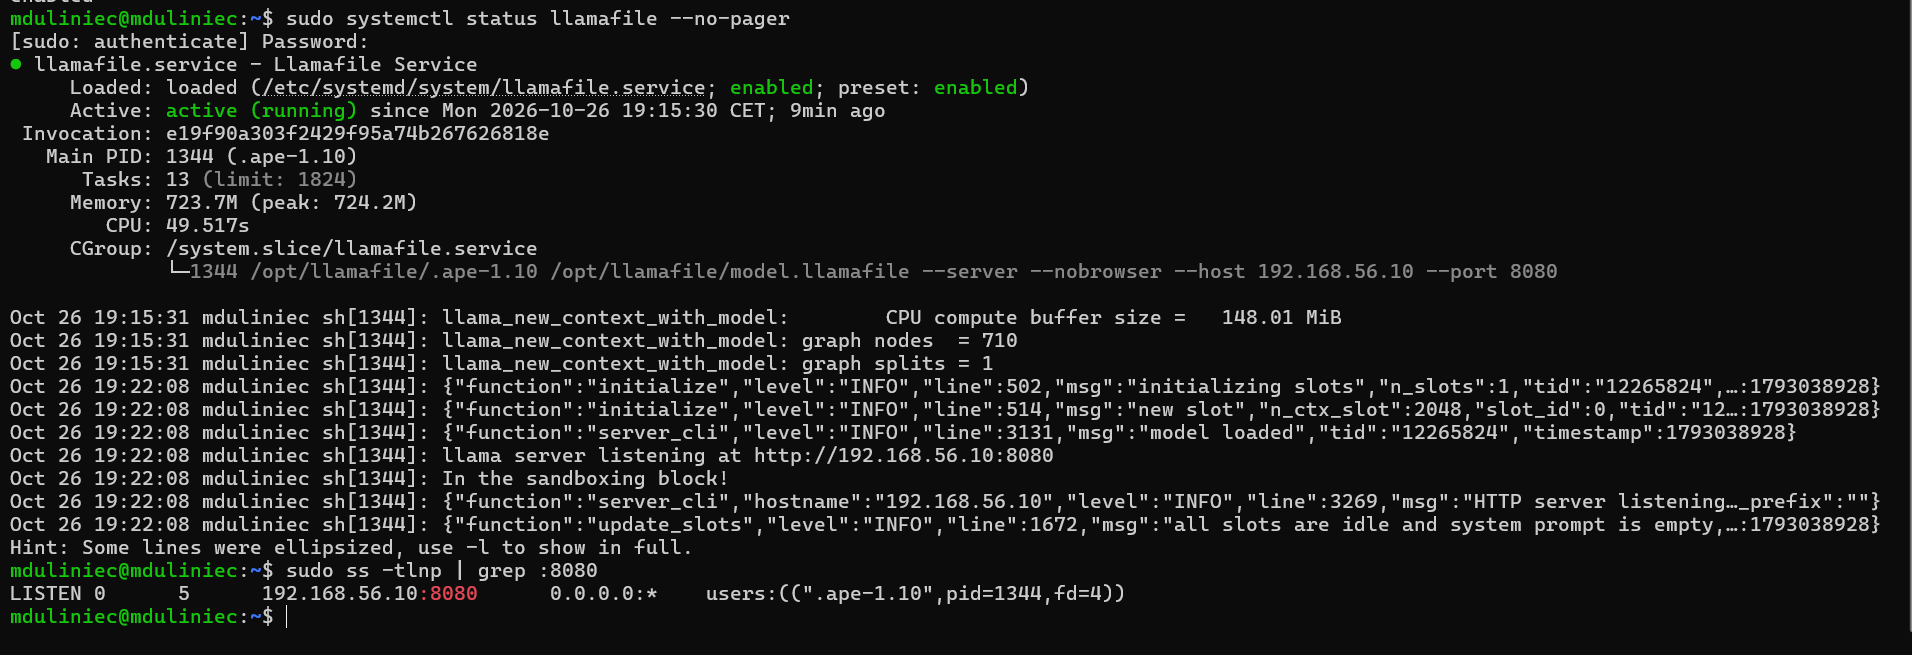